In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

In [29]:
# read emails.csv 
df = pd.read_csv("datasets/emails.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    5728 non-null   str  
 1   spam    5728 non-null   int64
dtypes: int64(1), str(1)
memory usage: 89.6 KB


In [30]:
X = df["text"].values
y = df[["spam"]].values

In [31]:
vec = TfidfVectorizer()
X = vec.fit_transform(X).toarray()

In [47]:
w = np.zeros(X.shape[1])
lr = 0.5
b = 0.0
th = 1
epochs = 15

In [48]:
# clean logic no ploting
# for e in range(epochs):
#     for i in range(X.shape[0]):
#         z = X[i].dot(w) + b
#         if z >= th:
#             pred = 1
#         else:
#             pred = 0

#         err = y[i] - pred
#         if err != 0:
#             w = w + lr * err * X[i]
#             b = b + lr * err


# print("Final Updated Weights and Bias: ", w,b)

In [49]:
# # Training Accuracy
# correct = 0
# for i in range(X.shape[0]):
#     z = np.dot(X[i],w) + b
#     if z >= th:
#         pred = 1
#     else:
#         pred = 0

#     if pred == y[i]:
#         correct += 1

# acc = (correct / len(y)) * 100
# print("Accuracy : ", acc)

In [53]:
accs = []

for e in range(epochs):

    # TRAIN
    for i in range(X.shape[0]):

        z = np.dot(X[i], w) + b

        if z >= th:
            pred = 1
        else:
            pred = 0

        err = y[i] - pred

        if err != 0:
            w = w + lr * err * X[i]
            b = b + lr * err

    # EVALUATE AFTER TRAINING
    correct = 0

    for i in range(X.shape[0]):

        z = np.dot(X[i], w) + b

        if z >= th:
            pred = 1
        else:
            pred = 0

        if pred == y[i]:
            correct += 1

    acc = (correct / X.shape[0]) * 100
    accs.append(acc)

In [54]:
print(accs)

[77.39175977653632, 77.35684357541899, 77.40921787709497, 78.0377094972067, 77.93296089385476, 77.96787709497207, 78.10754189944134, 78.17737430167597, 78.2122905027933, 78.66620111731844, 78.89315642458101, 78.77094972067039, 79.0677374301676, 79.55656424581005, 79.27723463687151]


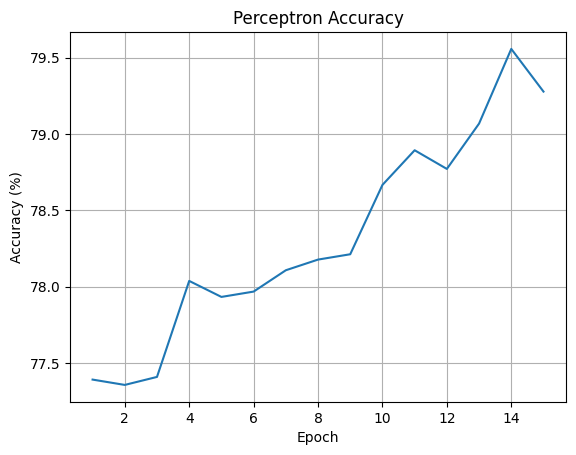

In [55]:
plt.plot(range(1, epochs + 1), accs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Perceptron Accuracy")
plt.grid()
plt.show()